# Model development

We build on the contextual exploration in Notebook 02 to predict UCLA loneliness scores. We compare models using all the prepared contextual measures, then examine what each type of friendship contact adds.

Model selection uses training-set cross-validation. The held-out sample has been inspected during model development, so we interpret the evaluation as exploratory.

## 1 Import libraries and set paths

We use separate folders for the modelling tables and figures.

In [3]:
from pathlib import Path
import hashlib
import sklearn
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
processed = root / "data/processed"
tables = root / "results/tables/modelling"
figures = root / "results/figures/presentation2"
for folder in (tables, figures):
    folder.mkdir(parents=True, exist_ok=True)
from IPython.display import display

## 2 Load the sample and define predictor sets

Loneliness may relate to relationships, health and wider circumstances. We use the contextual measures prepared in Notebook 01, including the four separate support items, family contact and participation.

Age and cleaned counts are numerical predictors. We one-hot encode the response categories, including ordered contact, support and health responses. This lets each category have its own relationship with the score without assuming equal changes between adjacent codes. Missing categorical answers receive a separate category. Missing numerical predictors use training medians and missingness indicators.

In [4]:
sample_path = processed / "eu_loneliness_analysis_sample.csv"
sample = pd.read_csv(sample_path)
target = "ucla_total"
face, remote = "friends_meet_face", "friends_meet_tele"
numeric = ["age", "close_friends_n", "close_family_n", "adults_n",
           "childr_n_0to5", "childr_n_6to15", "others_n"]
context_categories = [
    "gender", "relationship", "education", "work_status", "municipality_type", "country",
    "health_general", "health_condition",
    "social_support_a", "social_support_b", "social_support_c", "social_support_d",
    "family_meet_face", "family_meet_tele", "social_activities_a",
]
categorical = context_categories + [face, remote]
context = numeric + context_categories
full = context + [face, remote]
predictor_sets = {
    "Face-to-face only": [face], "Remote only": [remote],
    "Both contact types": [face, remote], "Context only": context,
    "Context + face-to-face": context + [face], "Context + remote": context + [remote],
    "Context + both": full,
}
assert sample["id_pers"].is_unique
assert sample["age"].ge(16).all()
assert sample[[face, remote, target]].notna().all().all()
assert sample[target].between(3, 9).all()
assert set(full).issubset(sample.columns)
assert len(full) == len(set(full))
assert not set(full).intersection(["id_pers", "w_eu27",
    "loneliness_ucla_a", "loneliness_ucla_b", "loneliness_ucla_c"])

# Notebook 01 already exports the observed response labels.
codebook = pd.read_csv(root / "results/tables/presentation1/observed_code_labels.csv")
codebook.loc[codebook["variable"].isin(categorical)].to_csv(
    tables / "predictor_response_labels.csv", index=False
)
availability = pd.DataFrame({
    "encoding": ["numeric" if c in numeric else "one-hot" for c in full],
    "valid_n": sample[full].notna().sum(),
    "missing_percent": sample[full].isna().mean() * 100,
}, index=full)
availability.to_csv(tables / "predictor_missingness.csv")
display(availability.round(2))

,encoding,valid_n,missing_percent
age,numeric,24431,0.00
close_friends_n,numeric,22925,6.16
close_family_n,numeric,23078,5.54
adults_n,numeric,24430,0.00
childr_n_0to5,numeric,24431,0.00
childr_n_6to15,numeric,24430,0.00
others_n,numeric,24431,0.00
gender,one-hot,24381,0.20
relationship,one-hot,24324,0.44
education,one-hot,24335,0.39


## 3 Split the data

We hold back 20% of respondents to estimate how well the fitted models predict scores for people they haven't seen. We use the same five training folds for every model so their validation scores are directly comparable.

In [5]:
train, test = train_test_split(sample.index.to_numpy(), test_size=0.2, random_state=42)
folds = KFold(n_splits=5, shuffle=True, random_state=42)
display(pd.Series({"training": len(train), "test": len(test)}, name="respondents"))
assert not set(train).intersection(test)
assert len(train) + len(test) == len(sample)

training    19544
test         4887
Name: respondents, dtype: int64

## 4 Set up preprocessing and model fitting

We keep preprocessing inside each fold so the validation rows cannot influence learned medians, scales or category lists. Numerical predictors are standardised for the linear models because Ridge penalties depend on coefficient size. Trees use the same encoded predictors without numerical scaling.

In [6]:
def compare(model, grid, features, scale=False):
    numbers = [name for name in features if name in numeric]
    categories = [name for name in features if name in categorical]
    numeric_steps = [SimpleImputer(strategy="median", add_indicator=True)]
    if scale:
        numeric_steps.append(StandardScaler())
    encoding = make_pipeline(
        SimpleImputer(strategy="constant", fill_value=-1),
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    )
    prep = ColumnTransformer([
        ("numeric", make_pipeline(*numeric_steps), numbers),
        ("categorical", encoding, categories),
    ])
    search = GridSearchCV(
        make_pipeline(prep, model), grid, cv=folds, n_jobs=2,
        scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error",
                 "r2": "r2"},
        refit="mae", return_train_score=True, error_score="raise",
    )
    search.fit(sample.loc[train, features], sample.loc[train, target])
    return search

## 5 Compare models

The mean and median baselines show how well we can predict using a single score for everyone. We choose the final model using cross-validation MAE because it expresses the average size of a prediction error in loneliness points.

,MAE,RMSE,R2,parameters
model,,,,
Ridge,1.220,1.526,0.320,{'ridge__alpha': 1}
Linear regression,1.220,1.526,0.320,{}
Random forest,1.232,1.527,0.319,"{'randomforestregressor__max_depth': None, 'ra..."
Decision tree,1.289,1.622,0.231,{'decisiontreeregressor__max_depth': 10}
Median baseline,1.558,1.850,-0.000,{}
Mean baseline,1.559,1.850,-0.000,{}


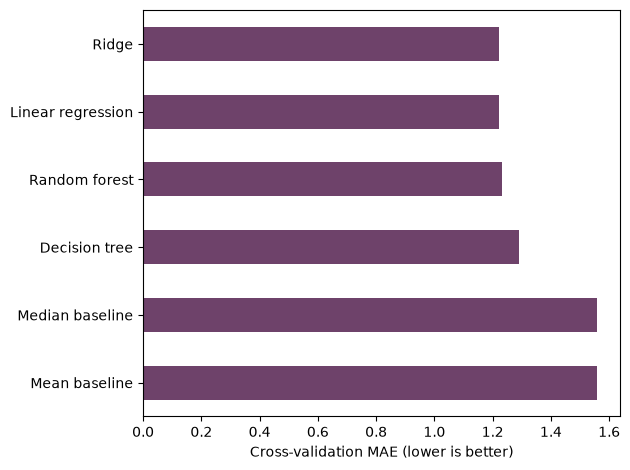

In [7]:
alpha_grid = {"ridge__alpha": [0.1, 1, 10, 100, 1000]}
candidates = {
    "Median baseline": (DummyRegressor(strategy="median"), {}, False),
    "Mean baseline": (DummyRegressor(strategy="mean"), {}, False),
    "Linear regression": (LinearRegression(), {}, True),
    "Ridge": (Ridge(), alpha_grid, True),
    "Decision tree": (DecisionTreeRegressor(min_samples_leaf=20, random_state=42),
                      {"decisiontreeregressor__max_depth": [2, 4, 6, 10, None]}, False),
    "Random forest": (RandomForestRegressor(n_estimators=150, max_features=0.7, random_state=42),
                      {"randomforestregressor__max_depth": [8, None],
                       "randomforestregressor__min_samples_leaf": [20, 80]}, False),
}
searches = {name: compare(model, grid, full, scale)
            for name, (model, grid, scale) in candidates.items()}

def cv_summary(fitted):
    rows = []
    for name, search in fitted.items():
        results = search.cv_results_
        i = search.best_index_
        rows.append({"model": name, "MAE": -results["mean_test_mae"][i],
                     "RMSE": -results["mean_test_rmse"][i], "R2": results["mean_test_r2"][i],
                     "parameters": str(search.best_params_)})
    return pd.DataFrame(rows).set_index("model").sort_values("MAE")

scores = cv_summary(searches)
selected = scores.index[0]
scores.to_csv(tables / "model_selection_cv.csv")
display(scores.round(3))
ax = scores["MAE"].sort_values(ascending=False).plot.barh(color="#6e426a")
ax.set(xlabel="Cross-validation MAE (lower is better)", ylabel="")
plt.tight_layout()
plt.savefig(figures / "01_model_comparison_cv.png", dpi=180)
plt.show()

## 6 Check tree depth

Deeper trees can fit the training data more closely, but that can also mean fitting patterns that don't carry over to new respondents. We plot training and validation MAE together to see where validation error starts to rise.

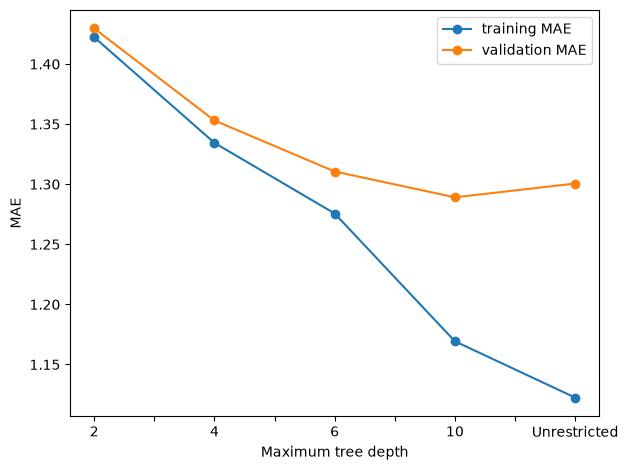

In [8]:
tree = pd.DataFrame(searches["Decision tree"].cv_results_)
tree["depth"] = tree["param_decisiontreeregressor__max_depth"].fillna("Unrestricted").astype(str)
tree["training MAE"] = -tree["mean_train_mae"]
tree["validation MAE"] = -tree["mean_test_mae"]
ax = tree.set_index("depth")[["training MAE", "validation MAE"]].plot(marker="o")
ax.set(xlabel="Maximum tree depth", ylabel="MAE")
plt.tight_layout()
plt.savefig(figures / "02_tree_complexity.png", dpi=180)
plt.show()

## 7 Compare predictor sets

We use Ridge for each predictor set so the model type stays consistent. Comparing context alone with context plus contact shows whether knowing how often people see or speak to friends improves predictions.

In [9]:
ridge_searches = {
    name: searches["Ridge"] if name == "Context + both" else compare(Ridge(), alpha_grid, features, True)
    for name, features in predictor_sets.items()
}
predictor_scores = cv_summary(ridge_searches)
predictor_scores.to_csv(tables / "predictor_sets_cv.csv")
display(predictor_scores.round(3))

,MAE,RMSE,R2,parameters
model,,,,
Context + face-to-face,1.220,1.525,0.320,{'ridge__alpha': 0.1}
Context + both,1.220,1.526,0.320,{'ridge__alpha': 1}
Context + remote,1.222,1.527,0.319,{'ridge__alpha': 1}
Context only,1.223,1.528,0.317,{'ridge__alpha': 0.1}
Both contact types,1.541,1.812,0.040,{'ridge__alpha': 0.1}
Face-to-face only,1.543,1.816,0.037,{'ridge__alpha': 0.1}
Remote only,1.554,1.825,0.027,{'ridge__alpha': 0.1}


## 8 Export the results and fitted models

We save the fitted models locally for Notebook 04.

In [10]:
for name, search in searches.items():
    filename = name.lower().replace(" ", "_") + "_grid.csv"
    pd.DataFrame(search.cv_results_).to_csv(tables / filename, index=False)

joblib.dump({
    "train": train, "test": test, "selected": selected,
    "sample_sha256": hashlib.sha256(sample_path.read_bytes()).hexdigest(),
    "sklearn_version": sklearn.__version__,
    "models": {name: searches[name].best_estimator_ for name in
               dict.fromkeys([selected, "Median baseline", "Mean baseline"])},
    "ridge_models": {name: search.best_estimator_ for name, search in ridge_searches.items()},
    "full": full, "predictor_sets": predictor_sets,
}, processed / "presentation2_models.joblib")

['/Users/ellabodkin/Documents/GitHub/ProjectCSC1169/data/processed/presentation2_models.joblib']

## 9 Summary

Ridge had the lowest cross-validation MAE (1.220), with ordinary linear regression almost identical. Its selected alpha was 1. The random forest's MAE was 1.232.

The wider predictor set builds on the contextual exploration in Presentation 1. Notebook 04 evaluates the selected model and compares what the friendship-contact measures add beyond those circumstances.
